# Trabajo Práctico Nº 1
## Objetivos

- Implementar y analizar el filtro de promedio móvil (moving average) en Python.
- Aplicar el concepto de convolución en señales digitales.
- Familiarizarse con el entorno de desarrollo en Python notebooks.
- Comparar representación en punto flotante vs punto fijo, evaluando precisión y tiempos de cómputo.

# Ejercicio 1 - Filtro Moving Average

1. Implementá un algoritmo de promedio móvil (moving average) según la definición vista en clase, que reciba como parámetros:

- La señal de entrada.
- El tamaño de la ventana.

A partir de tu implementación, obtené y graficá la respuesta impulsiva del sistema (lo que en clase llamamos su “firma” o función de transferencia).

2. Respondé:

- ¿Cómo se obtiene la respuesta impulsiva de cualquier sistema?
- ¿Qué representa en el caso del filtro de promedio móvil?

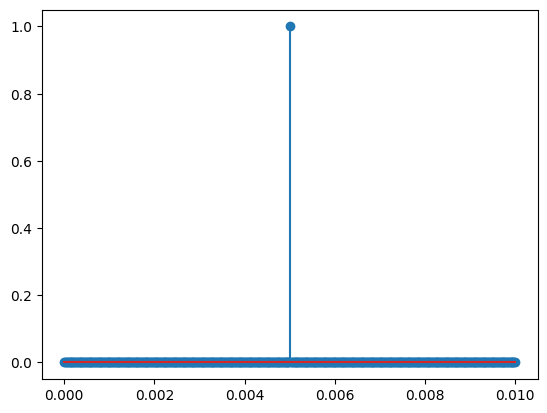

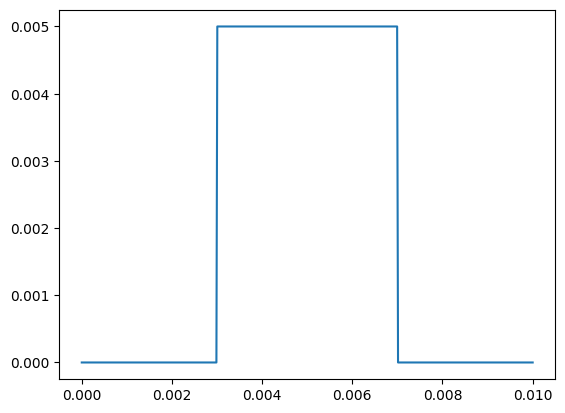

In [31]:
# Escribí tu código acá
from scipy import signal
import numpy as np
import matplotlib.pyplot as plt

def mediamovil(signal, ventana):
  av = np.zeros(N)
  for n in range(len(signal)):
    suma = 0
    d = 0
    for k in range (-(ventana), ventana):
        if ((n-k) > 0) and ((n-k) < (len(signal))):
            suma = suma + signal[(n-k)]
            d = d+1
    av[n] = suma/d
  return av


Fs = 50000   # Sampling Freq 50KHz
N = 500      # Samples number
t = np.linspace(0,N/Fs,num=N) # Crea una variable de tiempo desde 0, con intervalos de 1/Fs

#delta = np.zeros(len(t))
#delta[1] = 1

delta = signal.unit_impulse(len(t), 'mid')

plt.stem(t,delta)
plt.show()

rtasys =np.copy(mediamovil(delta,100))

plt.plot(t,rtasys)
plt.show()


# 1: la respuesta impulsiva de cualquier sistema se obtiene inyectando un impulso unitario, una delta de dirac.
# 2: Para el caso del filtro de media móvil, la respuesta al impulso es un escalón del ancho de la ventana del filtro y amplitud de 1/n, siendo n el ancho de la ventana.

# Ejercicio 2 - Respuesta del sistema

1. Genera dos señales de prueba:
    - Una onda cuadrada de amplitud 1 y frecuencia de 2 kHz.
    - Una onda triangular de amplitud 1 y frecuencia de 1 kHz.

Aplica el moving average implementado en el Ejercicio 1 a estas señales.

2. Analiza los resultados:

    - Grafica la señal original y la señal filtrada.
    - Explica qué cambios observas en la forma de onda.

3. Escribe tus conclusiones: ¿qué efecto tiene el filtro de promedio móvil sobre cada señal?


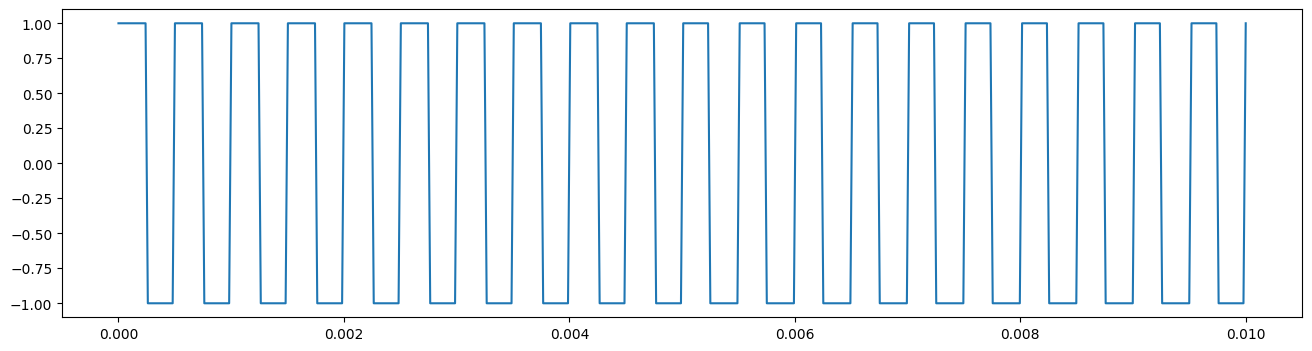

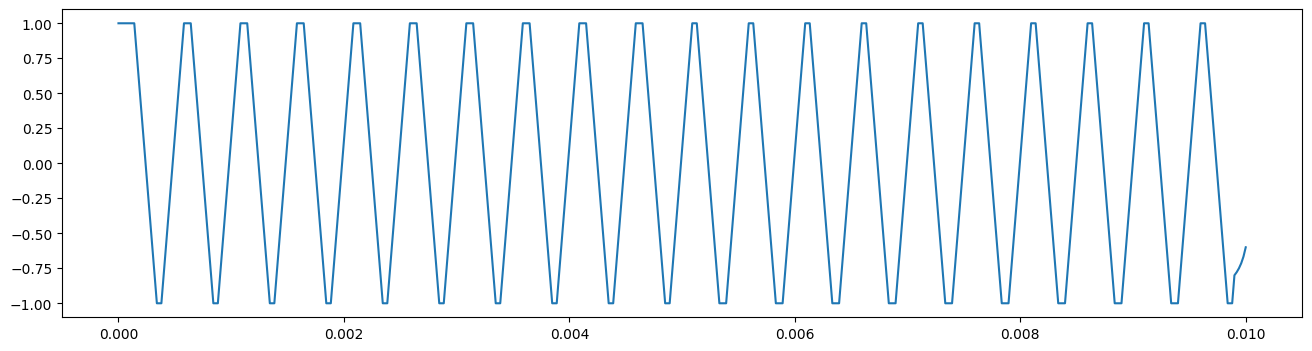

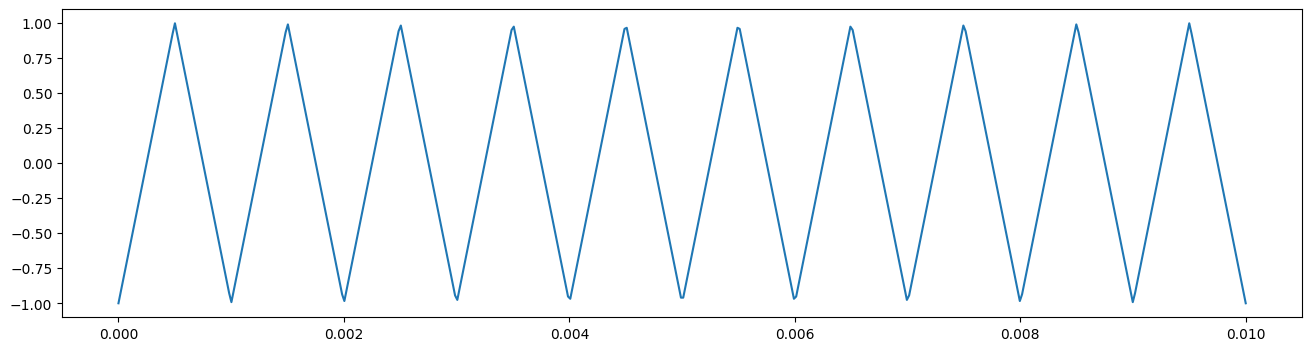

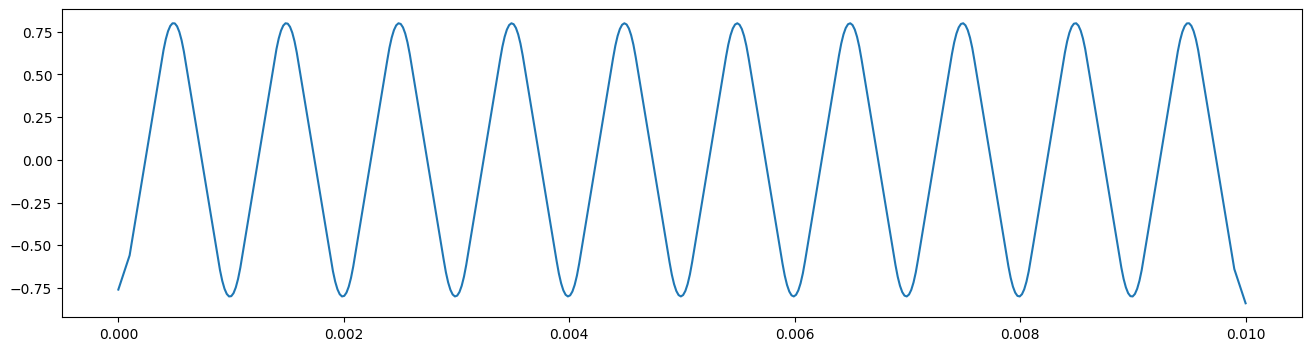

In [13]:
# Escribí tu código acá
from scipy import signal
import numpy as np
import matplotlib.pyplot as plt

Fs = 50000   # Sampling Freq 50KHz
N = 500      # Samples number
t = np.linspace(0,N/Fs,num=N) # Crea una variable de tiempo desde 0, con intervalos de 1/Fs

fc = 2000
ft = 1000

# Señal cuadrada
cuadrada = signal.square(2 * np.pi * fc * t)
plt.figure(figsize=(16, 4))
plt.plot(t,cuadrada)
plt.show()

filtrocudrada = np.copy(mediamovil(cuadrada,5))

plt.figure(figsize=(16, 4))
plt.plot(t,filtrocudrada)
plt.show()



# Señal triangular
triangular = signal.sawtooth(2 * np.pi * ft * t, 0.5)
plt.figure(figsize=(16, 4))
plt.plot(t,triangular)
plt.show()

filtrotriang = np.copy(mediamovil(triangular,5))

plt.figure(figsize=(16, 4))
plt.plot(t,filtrotriang)
plt.show()



El efecto observado en ambas señales es el suavizado de las mismas. En el caso de la señal cuadrada, se suavizan las pendientes abruptas, transformando la señal en trapezoidal o triangular dependiendo del ancho de la ventana. Para la señal triangular se observa el recorte de los picos, haciendo la señal más senoidal. El filtro de media móvil actúa como un filtro pasa bajos, eliminando los efectos de las componentes de alta frecuencia, cuanto más ancha la ventana del filtro, más baja la frecuencia de corte del filtro.

# Ejercicio 3 - Convolución en punto flotante y punto fijo

1. Implementa un algoritmo de convolución:

    - En punto flotante (float).
    - En punto fijo, utilizando la funcion fijo() de ejemplo.

2. Compara los resultados con la función de NumPy np.convolve. Mide y compara:

    - El tiempo de ejecución usando timeit.
    - El error de la salida respecto al cálculo en punto flotante.

3. Graficar todas las señales calculadas

4. Conclusión:

    - ¿Qué diferencias observas entre las implementaciones?
    - ¿Qué conclusiones se puede sacar de usar punto fijo vs punto flotante?

0.00040347600224777125
0.0016218260025198106
0.7543198720013606


/tmp/ipykernel_1005/2903504049.py:17: RuntimeWarning: overflow encountered in scalar multiply
  y[i] += x[i - j] * h[j]


1.8294078649996663
782010.745130848
32697.47415807867


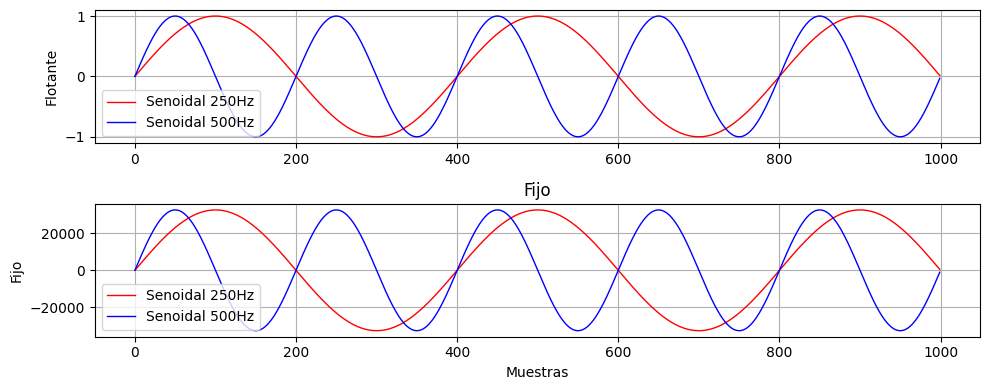

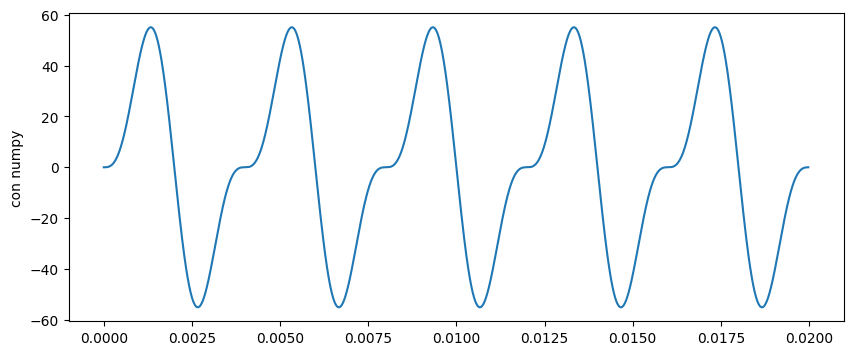

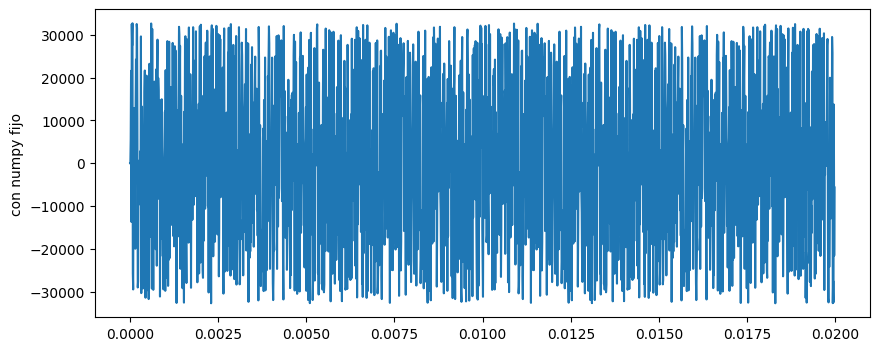

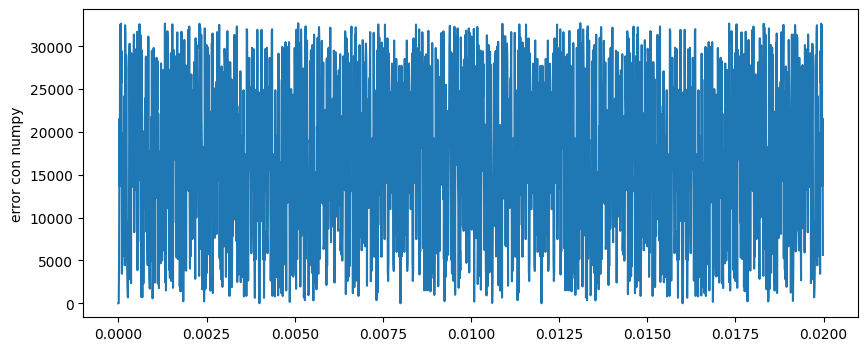

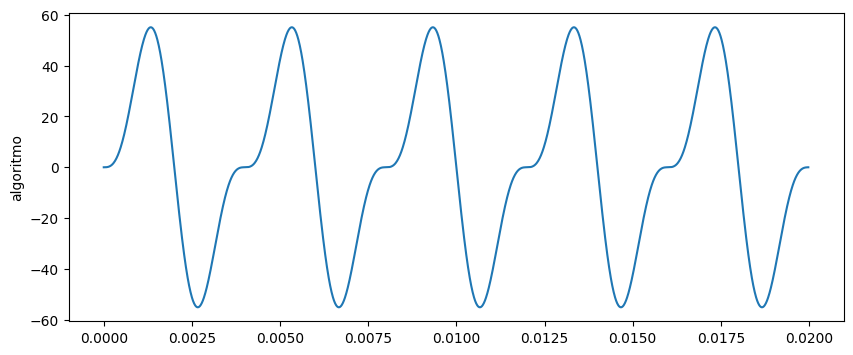

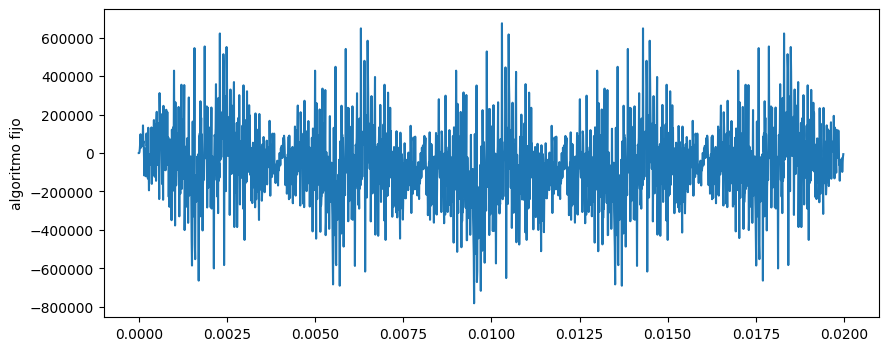

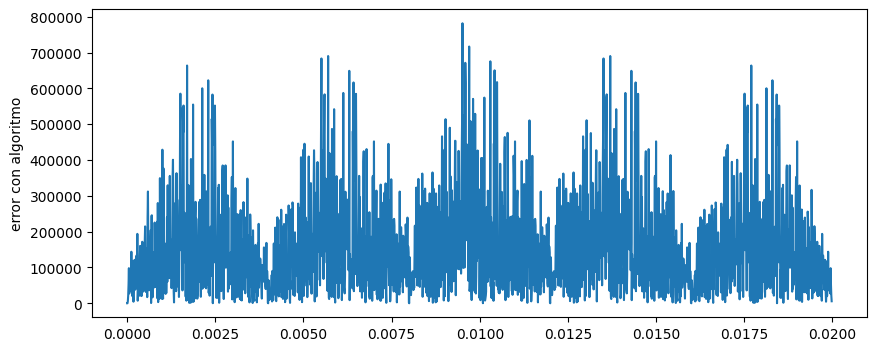

In [38]:
# Escribí tu código acá
import timeit
import time
import numpy as np
import matplotlib.pyplot as plt

def convolucion(x, h):

    N = len(x)
    M = len(h)

    y = np.zeros(N + M - 1)

    for i in range(len(y)):
        for j in range(M):
            if 0 <= i - j < N:
                y[i] += x[i - j] * h[j]

    return y

fs = 100000      # Frecuencia de muestreo
N = 1000        # Duración total
t = np.arange(0,N/fs,1/fs)

f1 = 250
f2 = 500

# Conversión a punto fijo
def fijo(x, frac_bits=15):
    """Convierte float a entero Q1.15 con saturación."""
    xf = np.round(x * (1 << frac_bits)).astype(np.int32)
    return np.clip(xf, -(1 << frac_bits), (1 << frac_bits) - 1).astype(np.int16)

x = np.sin(2*np.pi*f1*t)
y = np.sin(2*np.pi*f2*t)

xf = fijo(x)
yf = fijo(y)

#z = np.copy(convolucion(x,y))
#zf = np.copy(convolucion(xf,yf))
#znp = np.convolve(x,y)

def wrapper(func, *args):
    def wrapped():
        return func(*args)
    return wrapped

conv1 = wrapper(np.convolve, x, y)
print (timeit.timeit(conv1, number=1))

conv1f = wrapper(np.convolve, xf, yf)
print (timeit.timeit(conv1f, number=1))

conv2 = wrapper(convolucion, x, y)
print (timeit.timeit(conv2, number=1))

conv2f = wrapper(convolucion, xf, yf)
print (timeit.timeit(conv2f, number=1))

z = np.copy(convolucion(x,y))
zf = np.copy(convolucion(xf,yf))

e = np.abs(z-zf)
emax = np.max(e)
print(emax)

z1 = np.convolve(x,y)
z1f = np.convolve(xf,yf)

e1 = np.abs(z1-z1f)
e1max = np.max(e1)
print(e1max)

t2 = np.arange(0,len(z)/fs,1/fs)


plt.figure(figsize=(10, 4))
plt.subplot(2,1,1)
plt.plot(t*fs, x, label='Senoidal 250Hz', color='red', linewidth=1)
plt.plot(t*fs, y, label='Senoidal 500Hz', color='blue', linewidth=1)
plt.ylabel("Flotante")
plt.legend()
plt.grid(True)
plt.subplot(2,1,2)
plt.plot(t*fs, xf, label='Senoidal 250Hz', color='red', linewidth=1)
plt.plot(t*fs, yf, label='Senoidal 500Hz', color='blue', linewidth=1)
plt.legend()
plt.grid(True)
plt.title("Fijo")
plt.ylabel("Fijo")
plt.xlabel("Muestras")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(t2,z1)
plt.ylabel("con numpy")
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(t2,z1f)
plt.ylabel("con numpy fijo")
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(t2,e1)
plt.ylabel("error con numpy")
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(t2,z)
plt.ylabel("algoritmo")
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(t2,zf)
plt.ylabel("algoritmo fijo")
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(t2,e)
plt.ylabel("error con algoritmo")
plt.show()

Como diferencia se observa que la implementación con numpy es  mucho más rápida, y por tanto más eficiente computacionalmente, que la implementación de un algoritmo de convolución tal cual se describe en la teoría. Además en términos de tiempo, trabajar con punto flotante es más rápido que con punto fijo. Las señales producidas por los cálculos en punto fijo son, en ambos casos, extremadamente ruidosas. No guardan ningún parecido con las señales obtenidas con punto flotante.

Como conclusión se deduce que para este tipo de cálculo es mejor utilizar punto flotante


In [ ]:
# Ejemplos de medicion de tiempos
# %pylab inline
import timeit
import time
import numpy as np

t = np.arange(0, 1024/20000, 1/20000)
s1= np.sin(2*np.pi*1000*t)+1
s2 = np.sin(2*np.pi*1200*t)

# METODO 1 de medición de tiempos

# Este wrapper empaqueta funciones para que el timeit pueda medir solo eso
def wrapper(func, *args):
    def wrapped():
        return func(*args)
    return wrapped

conv = wrapper(np.convolve, s1, s2)
print (timeit.timeit(conv, number=1))

# METODO 2 de medición de tiempos
start = time.time()
conv_r = np.convolve(s1,s2)
end = time.time()
print (end-start)

0.00010390000534243882
0.00049591064453125


Float => Max: 1.0, Min: -1.0
Fijo => Max: 32767, Min: -32768


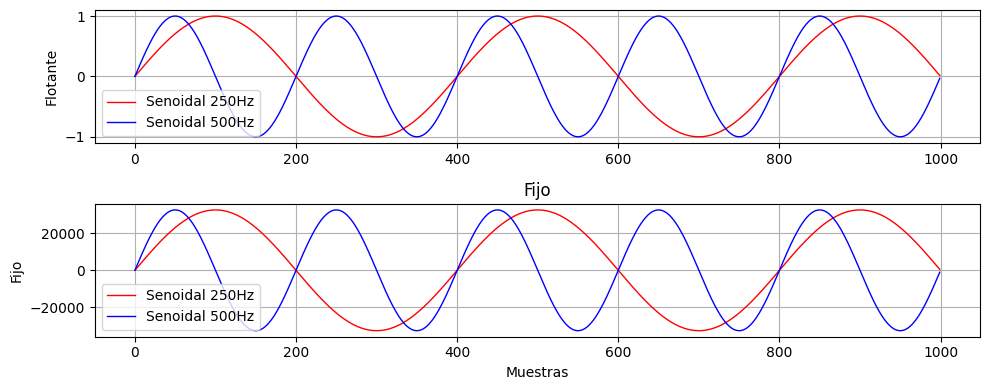

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import timeit

fs = 100000      # Frecuencia de muestreo
N = 1000        # Duración total
t = np.arange(0,N/fs,1/fs)

f1 = 250
f2 = 500

# Conversión a punto fijo
def fijo(x, frac_bits=15):
    """Convierte float a entero Q1.15 con saturación."""
    xf = np.round(x * (1 << frac_bits)).astype(np.int32)
    return np.clip(xf, -(1 << frac_bits), (1 << frac_bits) - 1).astype(np.int16)

x = np.sin(2*np.pi*f1*t)
y = np.sin(2*np.pi*f2*t)

xf = fijo(x)
yf = fijo(y)

print(f"Float => Max: {max(x)}, Min: {min(x)}")
print(f"Fijo => Max: {max(xf)}, Min: {min(xf)}")

plt.figure(figsize=(10, 4))
plt.subplot(2,1,1)
plt.plot(t*fs, x, label='Senoidal 250Hz', color='red', linewidth=1)
plt.plot(t*fs, y, label='Senoidal 500Hz', color='blue', linewidth=1)
plt.ylabel("Flotante")
plt.legend()
plt.grid(True)
plt.subplot(2,1,2)
plt.plot(t*fs, xf, label='Senoidal 250Hz', color='red', linewidth=1)
plt.plot(t*fs, yf, label='Senoidal 500Hz', color='blue', linewidth=1)
plt.legend()
plt.grid(True)
plt.title("Fijo")
plt.ylabel("Fijo")
plt.xlabel("Muestras")
plt.tight_layout()
plt.show()